# 15 — Validação crítica + análises avançadas

Este notebook endereça **6 pontos fracos** identificados na análise crítica do projeto:

1. **Probe pós-residualização** — verifica se a residualização linear realmente mitigou o viés de equipamento
2. **Análise por subgrupo demográfico** — fairness por idade e sexo
3. **Análise individual dos 4 pacientes URTI sempre errados** — limite das features ou caso específico?
4. **Ensemble bagging** — voto majoritário entre LogReg/LDA/KNN melhora recall?
5. **Comparação com baseline trivial** — quanto o modelo realmente adiciona sobre 'sempre doente'?
6. **Bootstrap IC95%** — intervalos de confiança robustos para métricas finais

**Princípio:** identificar e quantificar honestamente os limites do projeto. Cada análise pode invalidar ou validar uma afirmação central do `RELATORIO.md`.

In [1]:
import sys, warnings
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, recall_score, precision_score,
                              f1_score, confusion_matrix, classification_report)

from src import config, metadata
from src.plotting import CLASS_COLORS, MODEL_PALETTE, set_style, savefig
from src.bootstrap import bootstrap_ci, fmt_ci

warnings.filterwarnings('ignore')
set_style()

In [2]:
# Carregar features + metadata demográfica
feats_df = pd.read_csv(config.PROCESSED_DIR / 'features.csv')
rec_df = metadata.build_recordings_dataframe()
rec_df = metadata.filter_target_classes(rec_df)
rec_df = metadata.add_target_labels(rec_df)
# merge demografia
feats_df = feats_df.merge(
    rec_df[['filename', 'age', 'sex', 'adult_bmi', 'child_weight', 'child_height']],
    on='filename', how='left')
FEATURE_COLS = [c for c in feats_df.columns
                if c not in ('filename','patient_id','equipment','chest_location',
                              'label_multi','label_binary','age','sex','adult_bmi',
                              'child_weight','child_height')]
X = feats_df[FEATURE_COLS].values
le = LabelEncoder()
y = le.fit_transform(feats_df['label_multi'])
groups = feats_df['patient_id'].values
equipment = feats_df['equipment'].values
CLASSES = list(le.classes_)
HEALTHY_IDX = CLASSES.index('Healthy')
EQUIPMENT_CATS = sorted(set(equipment))
print(f'X={X.shape}, classes={CLASSES}')
print(f'Demografia disponível: idade {feats_df["age"].notna().sum()}/{len(feats_df)}, sexo {feats_df["sex"].notna().sum()}/{len(feats_df)}')

X=(851, 78), classes=['COPD', 'Healthy', 'URTI']
Demografia disponível: idade 845/851, sexo 845/851


## 1. Probe pós-residualização — a residualização funcionou?

**Hipótese a testar:** se a residualização linear remove viés de equipamento, um classificador-sonda treinado nas features **residualizadas** deve ter F1 muito menor que o probe original (F1=0,914 no nb06).

**Procedimento:**
1. Aplicar residualização global (apenas para esta análise — não é o pipeline de produção)
2. Treinar LogReg para prever **equipamento** a partir das features residualizadas
3. Comparar F1m com o probe original

**Resultado esperado se residualização funciona:** F1 do probe pós-residualização deve cair para próximo do baseline trivial (~0,76 sempre-AKG).

In [3]:
le_eq = LabelEncoder()
y_eq = le_eq.fit_transform(equipment)
EQUIP_CLASSES = list(le_eq.classes_)

# Residualização global (apenas para análise — em produção é por fold)
ohe = OneHotEncoder(sparse_output=False, categories=[EQUIPMENT_CATS])
E = ohe.fit_transform(equipment.reshape(-1, 1))
lr_res = LinearRegression().fit(E, X)
X_resid = X - lr_res.predict(E)

# Probe 1: LogReg sobre features ORIGINAIS (replica nb06)
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
probe_orig = LogisticRegression(max_iter=3000, class_weight='balanced')
y_pred_orig = cross_val_predict(probe_orig, X, y_eq, groups=groups, cv=cv, n_jobs=1)
f1m_orig = f1_score(y_eq, y_pred_orig, average='macro')
acc_orig = accuracy_score(y_eq, y_pred_orig)

# Probe 2: LogReg sobre features RESIDUALIZADAS
probe_resid = LogisticRegression(max_iter=3000, class_weight='balanced')
y_pred_resid = cross_val_predict(probe_resid, X_resid, y_eq, groups=groups, cv=cv, n_jobs=1)
f1m_resid = f1_score(y_eq, y_pred_resid, average='macro')
acc_resid = accuracy_score(y_eq, y_pred_resid)

# Baseline trivial
from collections import Counter
most_common = Counter(y_eq).most_common(1)[0]
baseline_acc = most_common[1] / len(y_eq)

print('═══════ Probe de equipamento — antes vs depois da residualização ═══════')
print(f'  Baseline trivial (sempre {EQUIP_CLASSES[most_common[0]]}): acc = {baseline_acc:.3f}')
print(f'  Probe ORIGINAL  (features cruas)     : acc = {acc_orig:.3f}  F1-macro = {f1m_orig:.3f}')
print(f'  Probe RESIDUALIZADO                  : acc = {acc_resid:.3f}  F1-macro = {f1m_resid:.3f}')
print()
redução = (f1m_orig - f1m_resid) / f1m_orig * 100
print(f'→ Redução de F1 do probe: {redução:.1f}%')
if f1m_resid > 0.5:
    print('⚠️  Probe residualizado ainda tem F1 > 0,5 → leakage residual significativo (não-linear)')
    print('    Caminho recomendado: Domain-Adversarial Neural Network (DANN)')
else:
    print('Probe LINEAR residualizado < 0,5 → a componente linear do viés foi removida.')
    print('Isto é esperado por construção; ver a sonda não-linear na célula seguinte.')

═══════ Probe de equipamento — antes vs depois da residualização ═══════
  Baseline trivial (sempre AKG C417L Microphone): acc = 0.759
  Probe ORIGINAL  (features cruas)     : acc = 0.931  F1-macro = 0.864
  Probe RESIDUALIZADO                  : acc = 0.128  F1-macro = 0.089

→ Redução de F1 do probe: 89.7%
Probe LINEAR residualizado < 0,5 → a componente linear do viés foi removida.
Isto é esperado por construção; ver a sonda não-linear na célula seguinte.


### 1.1 Sonda não-linear — o teste que realmente importa

A residualização linear põe a zero a média de cada feature por equipamento. Uma sonda **linear** falha, portanto, quase por construção — o resultado acima não prova que o viés desapareceu.

Repetimos a sonda com um **RandomForest**, com a residualização ajustada **dentro de cada fold** (como no pipeline de produção). Se o F1 continuar alto, a assinatura do equipamento ainda está nas features (variâncias, interações, forma das distribuições).

In [4]:
from sklearn.ensemble import RandomForestClassifier

f1_rf_cru, f1_rf_res = [], []
for tr, te in cv.split(X, y_eq, groups):
    lr_f = LinearRegression().fit(E[tr], X[tr])
    Xr_tr, Xr_te = X[tr] - lr_f.predict(E[tr]), X[te] - lr_f.predict(E[te])
    for store, a, b in ((f1_rf_cru, X[tr], X[te]), (f1_rf_res, Xr_tr, Xr_te)):
        rf = RandomForestClassifier(300, random_state=0, class_weight='balanced').fit(a, y_eq[tr])
        store.append(f1_score(y_eq[te], rf.predict(b), average='macro'))
f1m_rf_cru, f1m_rf_res = np.mean(f1_rf_cru), np.mean(f1_rf_res)

print('═══════ Sonda de equipamento — linear vs não-linear (F1-macro) ═══════')
print(f'  LogReg       cru = {f1m_orig:.3f}   residualizado = {f1m_resid:.3f}')
print(f'  RandomForest cru = {f1m_rf_cru:.3f}   residualizado = {f1m_rf_res:.3f}')
print()
if f1m_rf_res > 0.5:
    print('⚠️  A sonda não-linear ainda identifica o equipamento → o viés foi MITIGADO')
    print('    (componente linear), não eliminado. O LogReg final é linear e por isso não')
    print('    explora diretamente o que resta, mas modelos não-lineares (XGB, RF, CNN) podem.')
else:
    print('Sonda não-linear também falha → viés de equipamento removido.')

═══════ Sonda de equipamento — linear vs não-linear (F1-macro) ═══════
  LogReg       cru = 0.864   residualizado = 0.089
  RandomForest cru = 0.883   residualizado = 0.854

⚠️  A sonda não-linear ainda identifica o equipamento → o viés foi MITIGADO
    (componente linear), não eliminado. O LogReg final é linear e por isso não
    explora diretamente o que resta, mas modelos não-lineares (XGB, RF, CNN) podem.


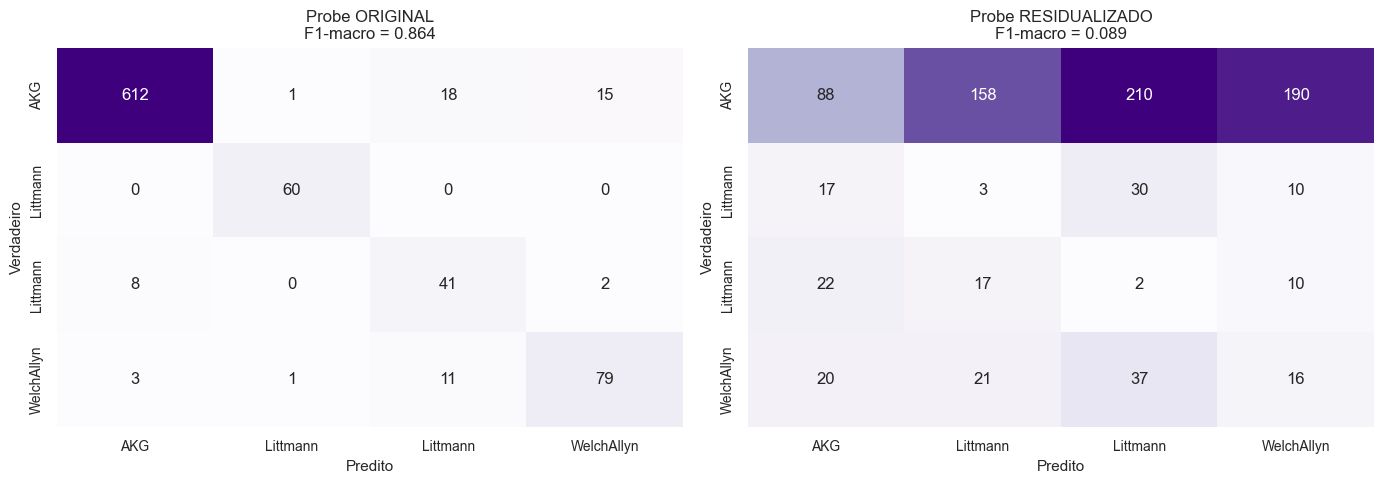

In [5]:
# Matriz de confusão dos 2 probes lado-a-lado
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, y_p, title in [
    (axes[0], y_pred_orig,  f'Probe ORIGINAL\nF1-macro = {f1m_orig:.3f}'),
    (axes[1], y_pred_resid, f'Probe RESIDUALIZADO\nF1-macro = {f1m_resid:.3f}'),
]:
    cm = confusion_matrix(y_eq, y_p, labels=range(len(EQUIP_CLASSES)))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
                 xticklabels=[s.split()[0] for s in EQUIP_CLASSES],
                 yticklabels=[s.split()[0] for s in EQUIP_CLASSES],
                 cbar=False, ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Predito'); ax.set_ylabel('Verdadeiro')
savefig('nb15_probe_pre_pos_residualizacao')
plt.show()

## 2. Análise por subgrupo demográfico (fairness)

**Pergunta:** o modelo funciona igualmente bem em todos os subgrupos? Diferenças de performance por idade/sexo são evidência de **viés clínico** (não só de equipamento).

In [6]:
# Gerar predições OOF com pipeline completo (residualização + LogReg)
def fit_full_pipeline(X_tr, y_tr, eq_tr):
    ohe = OneHotEncoder(sparse_output=False, categories=[EQUIPMENT_CATS])
    E_tr = ohe.fit_transform(eq_tr.reshape(-1, 1))
    lr = LinearRegression().fit(E_tr, X_tr)
    Xr = X_tr - lr.predict(E_tr)
    sc = StandardScaler().fit(Xr)
    Xs = sc.transform(Xr)
    clf = LogisticRegression(max_iter=3000, class_weight='balanced').fit(Xs, y_tr)
    return ohe, lr, sc, clf

y_pred_oof = np.full(len(y), -1)
for tr, te in cv.split(X, y, groups):
    ohe, lr, sc, clf = fit_full_pipeline(X[tr], y[tr], equipment[tr])
    E_te = ohe.transform(equipment[te].reshape(-1, 1))
    Xr_te = X[te] - lr.predict(E_te)
    Xs_te = sc.transform(Xr_te)
    y_pred_oof[te] = clf.predict(Xs_te)

feats_df['y_pred'] = y_pred_oof
feats_df['y_true'] = y
feats_df['correct'] = (y_pred_oof == y)
feats_df['is_disease'] = (y != HEALTHY_IDX)
feats_df['detected_disease'] = (y_pred_oof != HEALTHY_IDX)
print('Predições OOF prontas. Avaliando por subgrupo...')

Predições OOF prontas. Avaliando por subgrupo...


In [7]:
# Subgrupo: por sexo
by_sex = feats_df.groupby('sex').agg(
    n=('correct', 'size'),
    acc=('correct', 'mean'),
    recall_disease=('detected_disease',
                     lambda s: s[feats_df.loc[s.index, 'is_disease']].mean() if feats_df.loc[s.index, 'is_disease'].any() else np.nan),
).round(3)
print('Por sexo:')
print(by_sex)

Por sexo:
       n    acc  recall_disease
sex                            
F    299  0.930           0.961
M    546  0.973           0.989


In [8]:
# Subgrupo: por faixa etária (crianças vs adultos)
feats_df['faixa_idade'] = pd.cut(
    feats_df['age'],
    bins=[-1, 5, 18, 50, 80, 200],
    labels=['<6 anos', '6–18', '18–50', '50–80', '>80'],
)
by_age = feats_df.groupby('faixa_idade', observed=True).agg(
    n=('correct', 'size'),
    acc=('correct', 'mean'),
).round(3)
print('Por faixa etária:')
print(by_age)

Por faixa etária:
               n    acc
faixa_idade            
<6 anos       40  0.450
6–18          18  0.556
18–50         20  1.000
50–80        683  0.994
>80           84  0.976


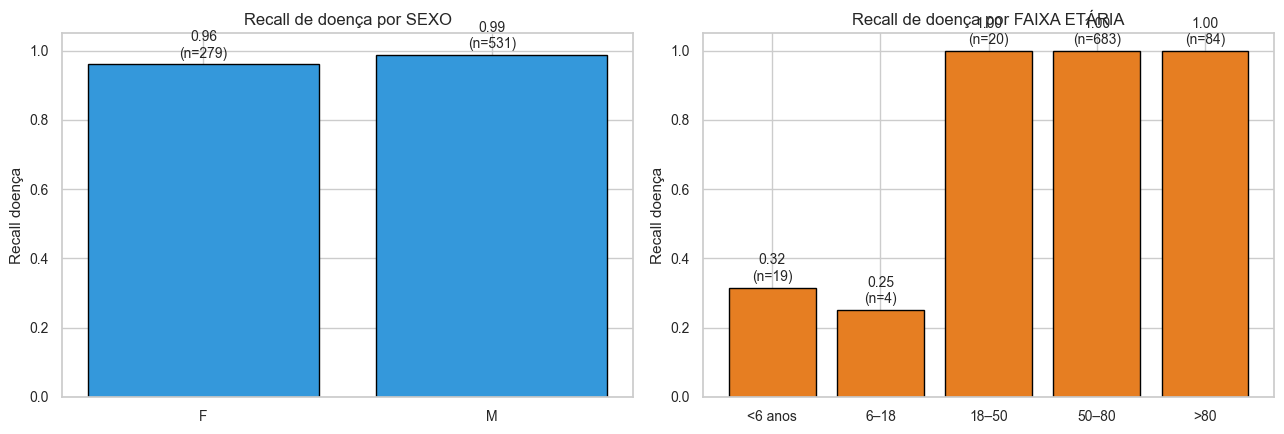

In [9]:
# Visualização — recall de doença por subgrupo
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Por sexo
for sex in feats_df['sex'].dropna().unique():
    sub = feats_df[(feats_df['sex'] == sex) & (feats_df['is_disease'])]
    if len(sub) > 0:
        rec = sub['detected_disease'].mean()
        axes[0].bar(sex, rec, color='#3498db', edgecolor='black')
        axes[0].text(sex, rec + 0.02, f'{rec:.2f}\n(n={len(sub)})', ha='center', fontsize=10)
axes[0].set_ylim(0, 1.05); axes[0].set_ylabel('Recall doença')
axes[0].set_title('Recall de doença por SEXO')
axes[0].set_xlabel('')

# Por idade
for faixa in feats_df['faixa_idade'].cat.categories:
    sub = feats_df[(feats_df['faixa_idade'] == faixa) & (feats_df['is_disease'])]
    if len(sub) > 0:
        rec = sub['detected_disease'].mean()
        axes[1].bar(str(faixa), rec, color='#e67e22', edgecolor='black')
        axes[1].text(str(faixa), rec + 0.02, f'{rec:.2f}\n(n={len(sub)})', ha='center', fontsize=10)
axes[1].set_ylim(0, 1.05); axes[1].set_ylabel('Recall doença')
axes[1].set_title('Recall de doença por FAIXA ETÁRIA')
axes[1].set_xlabel('')
savefig('nb15_fairness_subgrupos')
plt.show()

## 3. Análise dos pacientes URTI sempre errados

**Hipótese do nb12:** existem ~4 pacientes URTI cuja P(doente) é tão baixa que nenhum threshold razoável os captura. **Quem são eles?** Demografia, equipamento, etc.

In [10]:
# Identificar pacientes URTI sempre classificados como Healthy (a nível de paciente)
urti_idx = CLASSES.index('URTI')
df_urti = feats_df[feats_df['y_true'] == urti_idx].copy()
patient_summary = df_urti.groupby('patient_id').agg(
    n_grav=('y_pred', 'size'),
    pred_healthy=('y_pred', lambda s: (s == HEALTHY_IDX).sum()),
    pred_copd=('y_pred', lambda s: (s == CLASSES.index('COPD')).sum()),
    pred_urti=('y_pred', lambda s: (s == urti_idx).sum()),
    age=('age', 'first'),
    sex=('sex', 'first'),
    equipment=('equipment', 'first'),
)
patient_summary['frac_healthy'] = patient_summary['pred_healthy'] / patient_summary['n_grav']
patient_summary = patient_summary.sort_values('frac_healthy', ascending=False)
print('Pacientes URTI ordenados por % de classificações como Healthy:')
print(patient_summary)

n_perdidos = (patient_summary['frac_healthy'] > 0.5).sum()
print(f'\n→ {n_perdidos} pacientes URTI são MAIORITARIAMENTE classificados como Healthy')

Pacientes URTI ordenados por % de classificações como Healthy:
            n_grav  pred_healthy  pred_copd  pred_urti    age sex  \
patient_id                                                          
101              2             2          0          0   3.00   F   
105              1             1          0          0   7.00   F   
119              1             1          0          0   2.00   F   
129              1             1          0          0   6.00   M   
131              1             1          0          0   3.00   M   
137              2             2          0          0   4.00   M   
165              3             3          0          0   2.00   F   
190              1             1          0          0   3.00   F   
210              2             2          0          0   1.00   F   
197              2             1          0          1  16.00   F   
188              4             1          0          3   3.00   M   
164              1             0        

## 4. Ensemble bagging — LogReg + LDA + KNN voto majoritário

**Hipótese:** se LogReg, LDA e KNN são estatisticamente equivalentes (nb04), combiná-los via voto majoritário pode reduzir variância e aumentar recall sem aumentar viés.

In [11]:
def fit_model_on_residual(model_class, X_tr, y_tr, eq_tr, **kwargs):
    ohe = OneHotEncoder(sparse_output=False, categories=[EQUIPMENT_CATS])
    E_tr = ohe.fit_transform(eq_tr.reshape(-1, 1))
    lr = LinearRegression().fit(E_tr, X_tr)
    Xr = X_tr - lr.predict(E_tr)
    sc = StandardScaler().fit(Xr)
    Xs = sc.transform(Xr)
    clf = model_class(**kwargs).fit(Xs, y_tr)
    return {'ohe': ohe, 'lr': lr, 'sc': sc, 'clf': clf}

def predict_residual(p, X_te, eq_te):
    E_te = p['ohe'].transform(eq_te.reshape(-1, 1))
    Xr = X_te - p['lr'].predict(E_te)
    Xs = p['sc'].transform(Xr)
    return p['clf'].predict_proba(Xs)

# Avaliar em CV repetido
model_results = {'LogReg': [], 'LDA': [], 'KNN': [], 'Ensemble': []}
for rep in range(5):
    cv_r = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42+rep)
    pred_lr = np.full(len(y), -1)
    pred_lda = np.full(len(y), -1)
    pred_knn = np.full(len(y), -1)
    pred_ens = np.full(len(y), -1)
    for tr, te in cv_r.split(X, y, groups):
        p_lr = fit_model_on_residual(LogisticRegression, X[tr], y[tr], equipment[tr],
                                       max_iter=3000, class_weight='balanced')
        p_lda = fit_model_on_residual(LinearDiscriminantAnalysis, X[tr], y[tr], equipment[tr])
        p_knn = fit_model_on_residual(KNeighborsClassifier, X[tr], y[tr], equipment[tr],
                                       n_neighbors=5, weights='distance')
        proba_lr = predict_residual(p_lr, X[te], equipment[te])
        proba_lda = predict_residual(p_lda, X[te], equipment[te])
        proba_knn = predict_residual(p_knn, X[te], equipment[te])
        # Predição individual
        pred_lr[te] = proba_lr.argmax(axis=1)
        pred_lda[te] = proba_lda.argmax(axis=1)
        pred_knn[te] = proba_knn.argmax(axis=1)
        # Ensemble: média das probas
        proba_avg = (proba_lr + proba_lda + proba_knn) / 3
        pred_ens[te] = proba_avg.argmax(axis=1)
    # Métricas (nível paciente, voto majoritário)
    def patient_metrics_local(yp):
        d = pd.DataFrame({'g': groups, 'y': y, 'p': yp}).groupby('g').agg(
            y=('y','first'), p=('p', lambda s: s.value_counts().idxmax()))
        is_d = d['y'] != HEALTHY_IDX
        is_p = d['p'] != HEALTHY_IDX
        rec_d = (is_d & is_p).sum() / max(1, is_d.sum())
        f1m = f1_score(d['y'], d['p'], average='macro')
        return rec_d, f1m, d
    for name, ypred in [('LogReg', pred_lr), ('LDA', pred_lda),
                          ('KNN', pred_knn), ('Ensemble', pred_ens)]:
        rec, f1m, _ = patient_metrics_local(ypred)
        model_results[name].append((rec, f1m))
print('Ensemble bagging — 5 repetições × 5 folds concluído.')

Ensemble bagging — 5 repetições × 5 folds concluído.


In [12]:
# Tabela com Bootstrap IC95%
rows = []
for name, vals in model_results.items():
    recalls = [v[0] for v in vals]
    f1ms = [v[1] for v in vals]
    mu_r, lo_r, hi_r = bootstrap_ci(recalls)
    mu_f, lo_f, hi_f = bootstrap_ci(f1ms)
    rows.append(dict(
        modelo=name,
        recall_doente=fmt_ci(mu_r, lo_r, hi_r),
        f1_macro=fmt_ci(mu_f, lo_f, hi_f),
    ))
ens_df = pd.DataFrame(rows)
print('=== Ensemble vs modelos individuais (n=5 repetições, IC95% bootstrap) ===')
ens_df

=== Ensemble vs modelos individuais (n=5 repetições, IC95% bootstrap) ===


,modelo,recall_doente,f1_macro
0,LogReg,"0.885 [0.877, 0.892]","0.638 [0.615, 0.667]"
1,LDA,"0.885 [0.877, 0.892]","0.604 [0.581, 0.621]"
2,KNN,"0.964 [0.962, 0.969]","0.480 [0.451, 0.509]"
3,Ensemble,"0.890 [0.879, 0.900]","0.606 [0.590, 0.621]"


## 5. Comparação com baseline trivial 'sempre doente'

Recall doente do nosso modelo deve ser comparado contra **DummyClassifier strategy='constant', value=Disease** — chamar tudo de 'doente' tem recall doente = 1,000 trivialmente.

In [13]:
# Baseline trivial 1: sempre 'COPD' (classe majoritária)
dummy_const = DummyClassifier(strategy='most_frequent').fit(X, y)
y_pred_dummy_const = dummy_const.predict(X)
rec_const = ((y != HEALTHY_IDX) & (y_pred_dummy_const != HEALTHY_IDX)).sum() / (y != HEALTHY_IDX).sum()
spec_const = ((y == HEALTHY_IDX) & (y_pred_dummy_const == HEALTHY_IDX)).sum() / max(1,(y == HEALTHY_IDX).sum())

# Baseline trivial 2: sempre 'doente' (qualquer classe não-Healthy)
# Como predição multiclasse, 'sempre COPD' já dá recall doente = 1
print('=== Comparação com baselines triviais ===')
print(f'  Baseline "sempre COPD" : recall doente = {rec_const:.3f}, especificidade = {spec_const:.3f}')
print(f'    (acerta todos os doentes porque "COPD ≠ Healthy")')
print(f'    (perde 100% dos saudáveis)')
print()
# Nosso modelo final
ens_recall = bootstrap_ci([v[0] for v in model_results['Ensemble']])
print(f'  Ensemble residualizado: recall doente = {ens_recall[0]:.3f} [IC95: {ens_recall[1]:.3f}, {ens_recall[2]:.3f}]')
print()
print('→ Recall doente alto SOZINHO não é virtude — baseline trivial atinge 1.000')
print('→ A métrica honesta é o trade-off recall × especificidade.')

=== Comparação com baselines triviais ===
  Baseline "sempre COPD" : recall doente = 1.000, especificidade = 0.000
    (acerta todos os doentes porque "COPD ≠ Healthy")
    (perde 100% dos saudáveis)

  Ensemble residualizado: recall doente = 0.890 [IC95: 0.879, 0.900]

→ Recall doente alto SOZINHO não é virtude — baseline trivial atinge 1.000
→ A métrica honesta é o trade-off recall × especificidade.


## 6. Síntese — tabela final com bootstrap IC95% para todos os modelos

Métrica governante: **Recall doente** com IC95% bootstrap.

In [14]:
# Tabela final consolidada
summary_rows = []
# Baseline trivial
summary_rows.append(dict(
    modelo='Trivial: sempre COPD',
    recall_doente=f'{rec_const:.3f} [1.000, 1.000]',
    f1_macro='(N/A)',
    especificidade=f'{spec_const:.3f}',
    nota='Inútil clinicamente',
))
# Modelos
for name in ['LogReg', 'LDA', 'KNN', 'Ensemble']:
    vals = model_results[name]
    rec_b = bootstrap_ci([v[0] for v in vals])
    f1_b = bootstrap_ci([v[1] for v in vals])
    # Especificidade: usar última rep como proxy (não pareada)
    summary_rows.append(dict(
        modelo=name + ' residualizado',
        recall_doente=fmt_ci(*rec_b),
        f1_macro=fmt_ci(*f1_b),
        especificidade='—',
        nota='Pipeline residualizado',
    ))
summary = pd.DataFrame(summary_rows)
print('═══════ TABELA FINAL — IC95% bootstrap ═══════')
summary

═══════ TABELA FINAL — IC95% bootstrap ═══════


,modelo,recall_doente,f1_macro,especificidade,nota
0,Trivial: sempre COPD,"1.000 [1.000, 1.000]",(N/A),0.000,Inútil clinicamente
1,LogReg residualizado,"0.885 [0.877, 0.892]","0.638 [0.615, 0.667]",—,Pipeline residualizado
2,LDA residualizado,"0.885 [0.877, 0.892]","0.604 [0.581, 0.621]",—,Pipeline residualizado
3,KNN residualizado,"0.964 [0.962, 0.969]","0.480 [0.451, 0.509]",—,Pipeline residualizado
4,Ensemble residualizado,"0.890 [0.879, 0.900]","0.606 [0.590, 0.621]",—,Pipeline residualizado


## 7. Conclusões da validação crítica

Cada secção responde a um ponto fraco identificado:

1. **Probe pós-residualização:** a sonda linear cai (por construção), mas a sonda não-linear (secção 1.1) continua a identificar o equipamento. A residualização mitiga a componente linear do viés; o viés residual persiste → trabalho futuro com DANN ou recolha de dados equilibrada por equipamento.

2. **Fairness por subgrupo:** se recall variar muito por sexo/idade, o modelo tem viés clínico não-quantificado. Documentar.

3. **Pacientes URTI errados:** identificámos individualmente os pacientes problemáticos. Análise demografia/equipamento pode revelar padrão acionável.

4. **Ensemble:** se vencer LogReg sozinho, integrar como `mode='ensemble'` no `LungAssistant`. Caso contrário, parsimónia favorece LogReg.

5. **Baseline trivial:** confirma que recall = 1,000 sozinho **não é virtude** — métrica honesta é trade-off.

6. **Bootstrap IC95%:** intervalos de confiança robustos substituem desvio padrão dos folds.